# Experimento 3 — A afinidade precisa de uma curva?

**Hipótese:** acrescentar afinidade² reduz o RMSE e a curvatura dos resíduos.

Referência: duas médias + afinidade. Candidato: os mesmos atributos + afinidade². Ambos têm intercepto, sem regularização ou busca. O grau 2 é a hipótese escolhida; os modelos continuam lineares nos coeficientes.

**Protocolo:** 5 dobras × 5 repetições, semente 2026; mesmas partições para os modelos, apenas `train.csv`, previsões cortadas em [0, 5].

O RMSE considera as cinco previsões fora da dobra (OOF) de cada linha separadamente. Só os gráficos usam a média dessas previsões. As partições compartilham treino: desvios e vitórias são descritivos, não testes de significância. As hipóteses vieram da exploração destes dados; não são confirmação independente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold

N_SPLITS = 5
N_REPEATS = 5
SEED = 2026
CLIP = True
N_BINS = 8  # Somente visualização; não modifica os modelos.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
df = pd.read_csv(ROOT / 'data' / 'train.csv')
genres = ['action', 'comedy', 'drama']
assert set(df['genre'].unique()).issubset(genres)
required = ['user_avg_stars', 'movie_avg_stars', 'stars'] + ['share_' + g for g in genres]
assert not df[required].isna().any().any()
df['affinity'] = [row['share_' + row['genre']] for _, row in df.iterrows()]
assert df['affinity'].between(0, 1).all()
y = df['stars'].to_numpy(dtype=float)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
display(df[['genre', 'share_action', 'share_comedy', 'share_drama', 'affinity']].head())
print(f'{len(df)} linhas; {N_SPLITS} folds × {N_REPEATS} repetições; semente {SEED}; corte: {CLIP}')
df['affinity2'] = df['affinity'] ** 2


,genre,share_action,share_comedy,share_drama,affinity
0,drama,0.315,0.501,0.184,0.184
1,action,0.180,0.151,0.669,0.180
2,action,0.701,0.258,0.041,0.701
3,action,0.700,0.204,0.096,0.700
4,action,0.621,0.257,0.122,0.621


4000 linhas; 5 folds × 5 repetições; semente 2026; corte: True


## 1. Comparação nas mesmas partições

Cada previsão vem de um ajuste que não viu aquela linha. Calculamos a equação explicitamente e verificamos valores finitos antes do corte.

In [2]:
def rmse(actual, predicted):
    return float(np.sqrt(np.mean((actual - predicted) ** 2)))

def predict_linear(model, X):
    prediction = np.sum(X * model.coef_, axis=1) + model.intercept_
    assert np.isfinite(prediction).all()
    return np.clip(prediction, 0, 5) if CLIP else prediction

candidates = {
    'Afinidade linear': ['user_avg_stars', 'movie_avg_stars', 'affinity'],
    'Afinidade quadrática': ['user_avg_stars', 'movie_avg_stars', 'affinity', 'affinity2'],
}
def evaluate(n_splits, seed):
    folds = list(RepeatedKFold(n_splits=n_splits, n_repeats=N_REPEATS, random_state=seed).split(df))
    predictions_by_repeat = {name: np.full((N_REPEATS, len(df)), np.nan) for name in candidates}
    rows = []
    for name, columns in candidates.items():
        X = df[columns].to_numpy(dtype=float)
        for fold, (train, valid) in enumerate(folds, start=1):
            model = LinearRegression().fit(X[train], y[train])
            pred = predict_linear(model, X[valid])
            predictions_by_repeat[name][(fold - 1) // n_splits, valid] = pred
            rows.append({'modelo': name, 'fold': fold,
                         'RMSE validação': rmse(y[valid], pred),
                         'RMSE treino': rmse(y[train], predict_linear(model, X[train]))})
    assert all(np.isfinite(values).all() for values in predictions_by_repeat.values())
    oof = pd.DataFrame({name: values.mean(axis=0) for name, values in predictions_by_repeat.items()})
    return oof, pd.DataFrame(rows), predictions_by_repeat

oof, by_fold, predictions_by_repeat = evaluate(N_SPLITS, SEED)
summary = by_fold.groupby('modelo', sort=False).agg(
    media_RMSE_folds=('RMSE validação', 'mean'),
    desvio_entre_folds=('RMSE validação', 'std'),
    media_RMSE_treino=('RMSE treino', 'mean'))
summary.insert(0, 'RMSE OOF repetido', [rmse(y, predictions_by_repeat[name]) for name in summary.index])
display(summary.round(4))
paired = by_fold.pivot(index='fold', columns='modelo', values='RMSE validação')
paired['Quadrática − linear'] = paired['Afinidade quadrática'] - paired['Afinidade linear']
display(paired.round(4))
print(f"Quadrática melhora em {int((paired['Quadrática − linear'] < 0).sum())}/{N_SPLITS * N_REPEATS} partições.")

,RMSE OOF repetido,media_RMSE_folds,desvio_entre_folds,media_RMSE_treino
modelo,,,,
Afinidade linear,0.6601,0.6599,0.0137,0.6591
Afinidade quadrática,0.6290,0.6288,0.0159,0.6277


modelo,Afinidade linear,Afinidade quadrática,Quadrática − linear
fold,,,
1,0.6544,0.6274,-0.0270
2,0.6589,0.6231,-0.0358
3,0.6485,0.6228,-0.0257
4,0.6832,0.6440,-0.0392
5,0.6542,0.6251,-0.0291
6,0.6720,0.6480,-0.0241
7,0.6716,0.6338,-0.0378
8,0.6493,0.6164,-0.0328
9,0.6619,0.6195,-0.0424


Quadrática melhora em 25/25 partições.


## 2. Resíduos após incluir curvatura

Comparamos afinidade por gênero e as duas médias, nas mesmas faixas e escalas. Resíduo positivo indica subestimação; `n` mostra o tamanho de cada grupo.

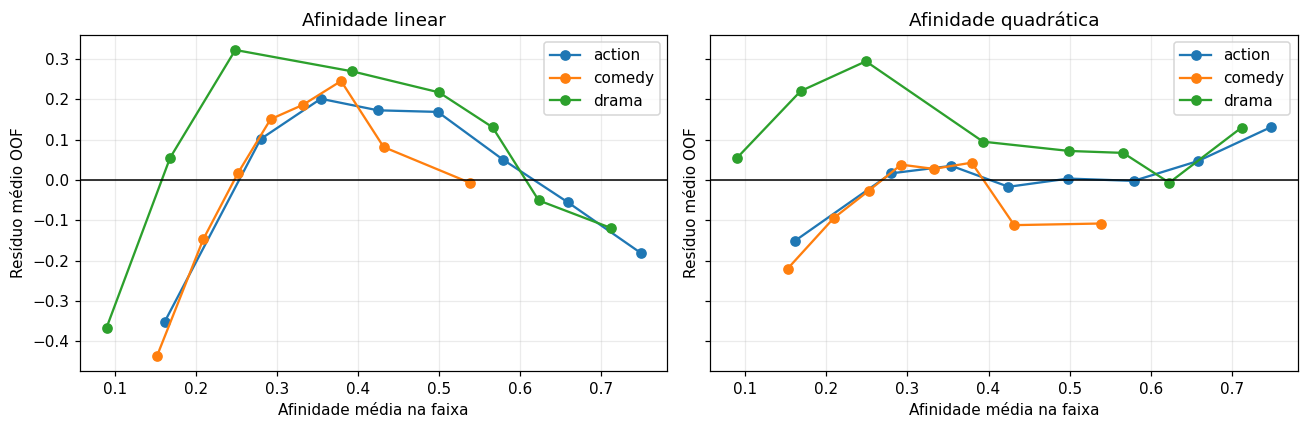

,x,residuo,n,modelo,genero
0,0.162,-0.352,184,Afinidade linear,action
1,0.280,0.101,184,Afinidade linear,action
2,0.354,0.201,180,Afinidade linear,action
3,0.425,0.173,183,Afinidade linear,action
4,0.498,0.169,183,Afinidade linear,action
5,0.579,0.050,182,Afinidade linear,action
6,0.658,-0.055,183,Afinidade linear,action
7,0.749,-0.181,183,Afinidade linear,action
8,0.152,-0.437,160,Afinidade linear,comedy
9,0.209,-0.147,154,Afinidade linear,comedy


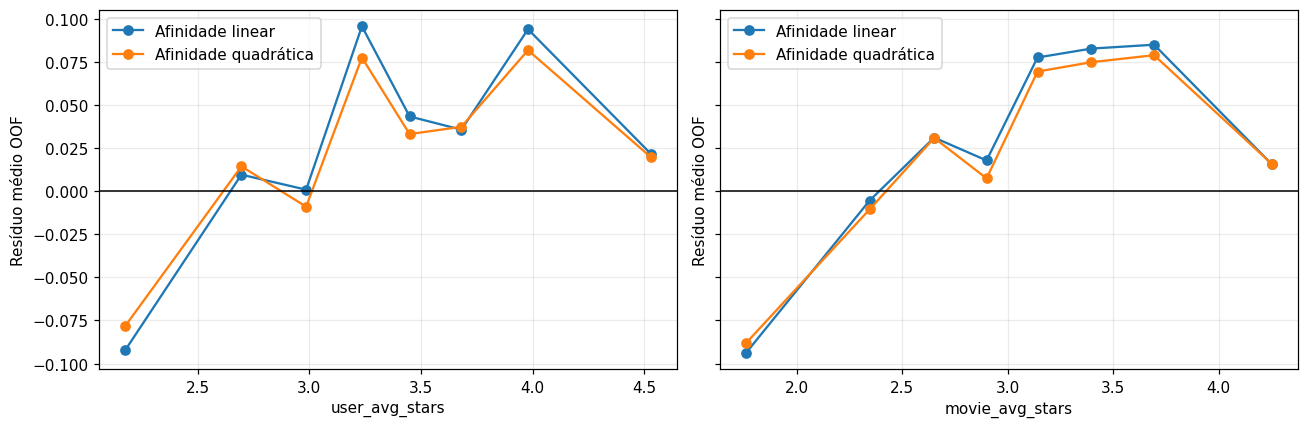

In [3]:
residuals = oof.apply(lambda prediction: y - prediction)
def binned(feature, name, index):
    sub = df.loc[index, [feature]].copy()
    sub['residuo'] = residuals.loc[index, name]
    return sub.groupby(pd.qcut(sub[feature], N_BINS, duplicates='drop'), observed=True).agg(
        x=(feature, 'mean'), residuo=('residuo', 'mean'), n=('residuo', 'size'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
tables = []
for ax, name in zip(axes, candidates):
    for genre in genres:
        table = binned('affinity', name, df.index[df['genre'].eq(genre)])
        ax.plot(table['x'], table['residuo'], 'o-', label=genre)
        tables.append(table.reset_index(drop=True).assign(modelo=name, genero=genre))
    ax.axhline(0, color='black', linewidth=1)
    ax.set(title=name, xlabel='Afinidade média na faixa', ylabel='Resíduo médio OOF')
    ax.legend()
plt.tight_layout()
plt.show()
display(pd.concat(tables, ignore_index=True).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, feature in zip(axes, ['user_avg_stars', 'movie_avg_stars']):
    for name in candidates:
        table = binned(feature, name, df.index)
        ax.plot(table['x'], table['residuo'], 'o-', label=name)
    ax.axhline(0, color='black', linewidth=1)
    ax.set(xlabel=feature, ylabel='Resíduo médio OOF')
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Conclusão do grupo

- A quadrática trouxe ganho relevante e consistente?
- Diminuiu o padrão por afinidade? Restam diferenças por gênero ou nas médias?

**A preencher após discussão.** Um padrão restante pode motivar outra hipótese; não demonstra que a regressão foi esgotada nem que todo erro seja previsível.

## Registro reproduzível desta execução

Salvamos previsões OOF por repetição, erros por partição, configurações selecionadas, versões e identificadores dos dados e do código em `results/rodada_atual`. Esses arquivos não se misturam aos resultados históricos.

In [4]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.current_results import save_run
save_run(ROOT, '05_hipotese_curvatura', df, y, predictions_by_repeat, by_fold,
         N_SPLITS, N_REPEATS, SEED, CLIP, globals().get('selections'))

Resultados verificados e salvos em /Users/insider/Desktop/movie-rating-prediction-main/results/rodada_atual/05_hipotese_curvatura.json


## Leitura da execução de 15 de novembro de 2026

A afinidade quadrática reduziu o RMSE de **0,660065 para 0,628989**, melhorando nas **25 partições** e nas cinco repetições. A curvatura ampla diminuiu, mas o resíduo médio de drama ficou em **+0,1158** e o de comédia em **−0,0574**. Ganho global não implica melhora de todo diagnóstico: o deslocamento entre gêneros persiste e motiva o notebook 06. Também restam padrões nas médias; a regressão não foi esgotada.

Esta leitura se refere à execução salva nesta rodada. Desvios e contagens são descritivos, não testes independentes. Revisar os números e o texto se dados, código ou configuração mudarem. As questões do grupo permanecem abertas à discussão.